In [31]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Note: you may need to restart the kernel to use updated packages.


In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [3]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5
hidden_units = 100

# Input to hidden layer weights and biases
w1 = torch.randn(Din, hidden_units) * std
b1 = torch.zeros(hidden_units)

# Hidden to output layer weights and biases
w2 = torch.randn(hidden_units, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-2  # Learning rate (Increased)
lr_decay = 0.99  # Learning rate decay
reg = 0.0  # Regularization
loss_history = []

In [4]:
# sigmoid function
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

# CrossEntropy Loss
def CrossEntropyLoss(y_pred, y_true):
    smooth = 1e-9
    loss = -torch.sum(y_true * torch.log(y_pred + smooth)) / y_true.shape[0]
    return loss

In [5]:
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot encoding

        # Forward pass with middle layer
        hidden = sigmoid(x_train.mm(w1) + b1)  # Middle layer with sigmoid activation
        y_pred = torch.softmax(hidden.mm(w2) + b2, dim=1) # Output layer activation

        # Loss calculation (CrossEntropy loss with regularization for both layers)
        loss = CrossEntropyLoss(y_pred, y_train_onehot)  # Cross-entropy loss
        loss += reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))  # Also add regularization term
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (y_pred - y_train_onehot) # Loss derivative
        dw2 = hidden.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        # Backpropagation to hidden layer
        dhidden = dy_pred.mm(w2.t()) * (hidden * (1 - hidden))  # Derivative of sigmoid
        dw1 = x_train.t().mm(dhidden) + reg * w1# 4. Plotting the Loss History
        db1 = dhidden.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1} / {iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

Epoch 1 / 10, Loss: 1.8812260065078736
Epoch 2 / 10, Loss: 1.6762846122980117
Epoch 3 / 10, Loss: 1.5810695818662643
Epoch 4 / 10, Loss: 1.5145286141633987
Epoch 5 / 10, Loss: 1.4582001338005066
Epoch 6 / 10, Loss: 1.4100849997997285
Epoch 7 / 10, Loss: 1.3710983256697655
Epoch 8 / 10, Loss: 1.3320957224965095
Epoch 9 / 10, Loss: 1.2973010202646256
Epoch 10 / 10, Loss: 1.2664901632070542


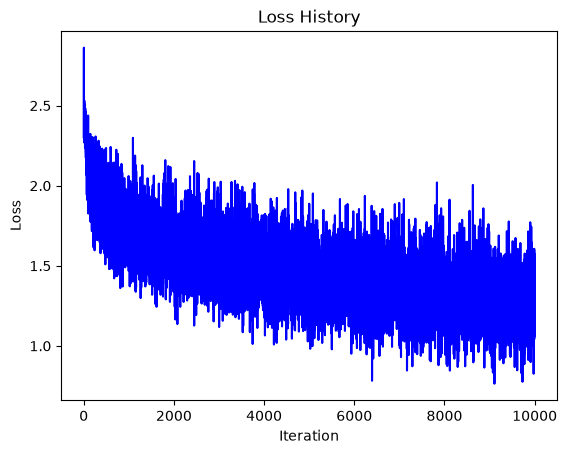

In [6]:
plt.figure()
plt.plot(loss_history, color='blue')
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [7]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden_layer = sigmoid(x_train.mm(w1) + b1)  # Middle layer with sigmoid activation
        y_train_pred = hidden_layer.mm(w2) + b2  # Output layer activation
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 58.04%


In [8]:
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden_layer = sigmoid(x_test.mm(w1) + b1)  # Middle layer with sigmoid activation
        y_test_pred = hidden_layer.mm(w2) + b2  # Output layer activation
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 47.69%


Question 2 - LeNet-5 Network

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define hyper parameters
BATCH_SIZE = 64
LEARNING_RATE = 0.01
NUM_EPOCHS = 10

# Select device
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [19]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load datasets
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [20]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.max_pool2d(x, kernel_size=2, stride=2)
        x = torch.relu(self.conv2(x))
        x = torch.max_pool2d(x, kernel_size=2, stride=2)
        x = x.view(-1, 16 * 5 * 5)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [21]:
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        # Layer 1: 28x28 -> 14x14
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Layer 2: 14x14 -> 7x7
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Layer 3: 7x7 -> 7x7 (No pooling to preserve spatial dimensions)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        
        self.dropout = nn.Dropout(0.5)
        
        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool2(torch.relu(self.bn2(self.conv2(x))))
        x = torch.relu(self.bn3(self.conv3(x)))
        
        x = x.view(x.size(0), -1) # Flatten
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [22]:
def train_and_evaluate(model, train_loader, test_loader, criterion, optimizer, num_epochs=10):
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    
    for epoch in range(num_epochs):
        # --- Training Phase ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
            
        history['train_loss'].append(train_loss / train_total)
        history['train_acc'].append(100 * train_correct / train_total)
        
        # --- Testing Phase ---
        model.eval()
        test_loss, test_correct, test_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()
                
        history['test_loss'].append(test_loss / test_total)
        history['test_acc'].append(100 * test_correct / test_total)
        
        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}% | "
              f"Test Loss: {history['test_loss'][-1]:.4f}, Test Acc: {history['test_acc'][-1]:.2f}%")
              
    return history



In [23]:
def plot_history(hist, title):
    epochs = range(1, NUM_EPOCHS + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.plot(epochs, hist['train_loss'], label='Train Loss', marker='o')
    ax1.plot(epochs, hist['test_loss'], label='Test Loss', marker='o')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epoch')
    ax1.legend()
    
    ax2.plot(epochs, hist['train_acc'], label='Train Acc', marker='o')
    ax2.plot(epochs, hist['test_acc'], label='Test Acc', marker='o')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

In [24]:
def display_confusion_matrix(model, title):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{title} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

Epoch [1/10] Train Loss: 0.3539, Train Acc: 88.44% | Test Loss: 0.0815, Test Acc: 97.36%
Epoch [2/10] Train Loss: 0.0678, Train Acc: 97.85% | Test Loss: 0.0463, Test Acc: 98.48%
Epoch [3/10] Train Loss: 0.0477, Train Acc: 98.47% | Test Loss: 0.0412, Test Acc: 98.62%
Epoch [4/10] Train Loss: 0.0368, Train Acc: 98.85% | Test Loss: 0.0357, Test Acc: 98.81%
Epoch [5/10] Train Loss: 0.0292, Train Acc: 99.05% | Test Loss: 0.0350, Test Acc: 98.88%
Epoch [6/10] Train Loss: 0.0245, Train Acc: 99.20% | Test Loss: 0.0329, Test Acc: 99.00%
Epoch [7/10] Train Loss: 0.0213, Train Acc: 99.31% | Test Loss: 0.0313, Test Acc: 98.95%
Epoch [8/10] Train Loss: 0.0172, Train Acc: 99.45% | Test Loss: 0.0361, Test Acc: 98.94%
Epoch [9/10] Train Loss: 0.0149, Train Acc: 99.56% | Test Loss: 0.0367, Test Acc: 98.91%
Epoch [10/10] Train Loss: 0.0116, Train Acc: 99.63% | Test Loss: 0.0318, Test Acc: 99.02%
Epoch [1/10] Train Loss: 0.1481, Train Acc: 95.23% | Test Loss: 0.0385, Test Acc: 98.75%
Epoch [2/10] Train L

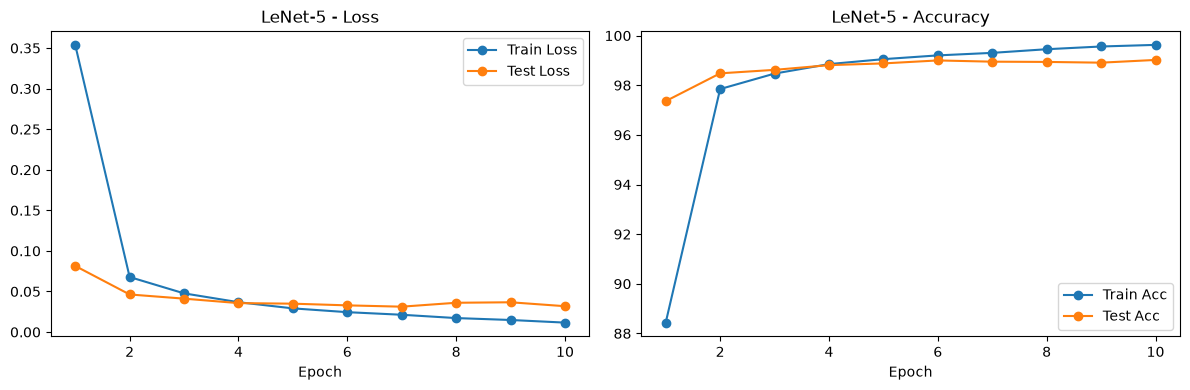

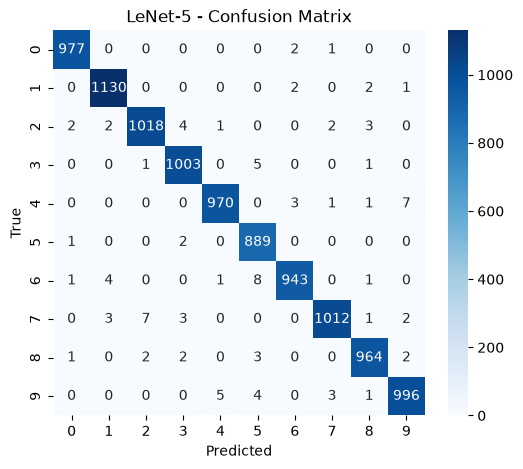

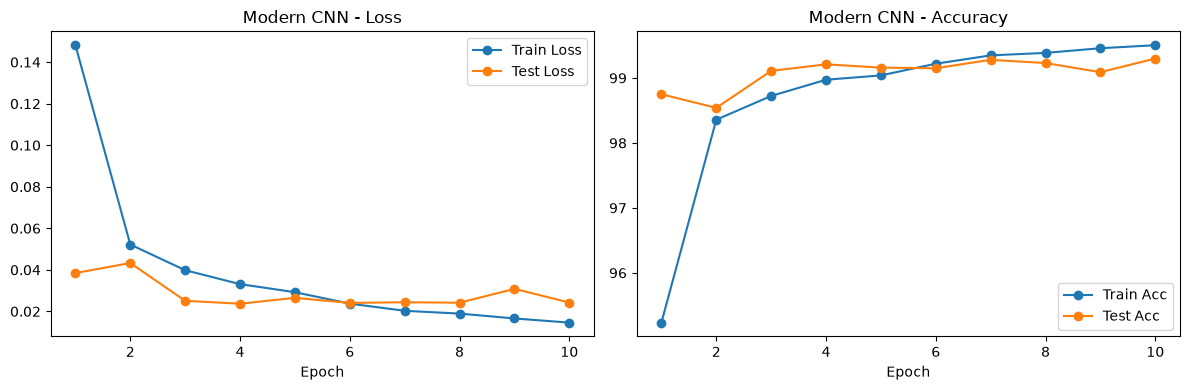

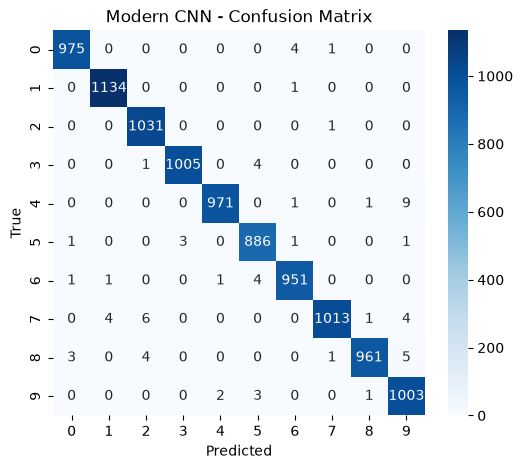

In [34]:
criterion = nn.CrossEntropyLoss()

lenet_model = LeNet5().to(device)
lenet_opt = torch.optim.SGD(
    lenet_model.parameters(), lr=LEARNING_RATE, momentum=0.9
)
lenet_history = train_and_evaluate(
    lenet_model, train_loader, test_loader,
    criterion, lenet_opt, NUM_EPOCHS
)

modern_model = ModernCNN().to(device)
modern_opt = torch.optim.SGD(
    modern_model.parameters(), lr=LEARNING_RATE, momentum=0.9
)
modern_history = train_and_evaluate(
    modern_model, train_loader, test_loader,
    criterion, modern_opt, NUM_EPOCHS
)

plot_history(lenet_history, "LeNet-5")
display_confusion_matrix(lenet_model, "LeNet-5")

plot_history(modern_history, "Modern CNN")
display_confusion_matrix(modern_model, "Modern CNN")

Question 3

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()

In [ ]:
!curl -O https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -q hymenoptera_data.zip

In [39]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Load dataset
data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=2)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

# Set device
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


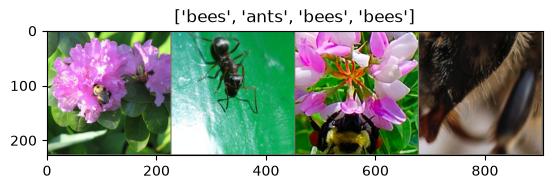

In [40]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

In [49]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.float() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:3f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model

In [50]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

In [51]:
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [52]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.5208 Acc: 0.7500
val Loss: 0.4287 Acc: 0.8105

Epoch 1/24
----------
train Loss: 0.6584 Acc: 0.7500
val Loss: 0.3820 Acc: 0.8366

Epoch 2/24
----------
train Loss: 0.5778 Acc: 0.7336
val Loss: 0.2772 Acc: 0.8954

Epoch 3/24
----------
train Loss: 0.4554 Acc: 0.8197
val Loss: 0.2696 Acc: 0.9085

Epoch 4/24
----------
train Loss: 0.3572 Acc: 0.8525
val Loss: 0.4376 Acc: 0.8497

Epoch 5/24
----------
train Loss: 0.4273 Acc: 0.8074
val Loss: 0.3763 Acc: 0.8693

Epoch 6/24
----------
train Loss: 0.5775 Acc: 0.7992
val Loss: 0.3532 Acc: 0.8889

Epoch 7/24
----------
train Loss: 0.3746 Acc: 0.8566
val Loss: 0.2577 Acc: 0.9150

Epoch 8/24
----------
train Loss: 0.2404 Acc: 0.8852
val Loss: 0.2700 Acc: 0.9150

Epoch 9/24
----------
train Loss: 0.3597 Acc: 0.8361
val Loss: 0.2804 Acc: 0.9020

Epoch 10/24
----------
train Loss: 0.3200 Acc: 0.8770
val Loss: 0.2947 Acc: 0.9020

Epoch 11/24
----------
train Loss: 0.3129 Acc: 0.8607
val Loss: 0.2741 Acc: 0.8954

Ep

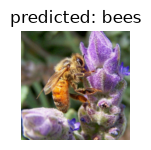

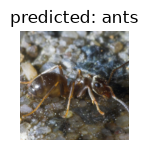

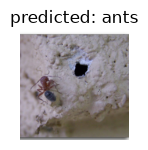

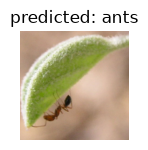

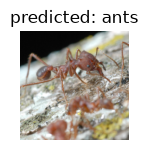

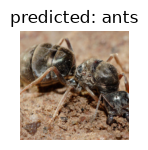

In [53]:
visualize_model(model_ft)

In [54]:
model_fe = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_fe.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_fe.fc.in_features
model_fe.fc = nn.Linear(num_ftrs, 2)

model_fe = model_fe.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_fe = optim.SGD(model_fe.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_fe, step_size=7, gamma=0.1)

In [55]:
model_fe = train_model(model_fe, criterion, optimizer_fe, exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.6084 Acc: 0.6311
val Loss: 0.3275 Acc: 0.8235

Epoch 1/24
----------
train Loss: 0.5777 Acc: 0.7090
val Loss: 0.3277 Acc: 0.8627

Epoch 2/24
----------
train Loss: 0.4144 Acc: 0.7951
val Loss: 0.1799 Acc: 0.9542

Epoch 3/24
----------
train Loss: 0.4104 Acc: 0.8115
val Loss: 0.2635 Acc: 0.9216

Epoch 4/24
----------
train Loss: 0.6486 Acc: 0.7377
val Loss: 0.2961 Acc: 0.8693

Epoch 5/24
----------
train Loss: 0.4613 Acc: 0.8156
val Loss: 0.2180 Acc: 0.9216

Epoch 6/24
----------
train Loss: 0.5074 Acc: 0.7869
val Loss: 0.1808 Acc: 0.9542

Epoch 7/24
----------
train Loss: 0.3323 Acc: 0.8402
val Loss: 0.1807 Acc: 0.9542

Epoch 8/24
----------
train Loss: 0.3744 Acc: 0.8361
val Loss: 0.1913 Acc: 0.9477

Epoch 9/24
----------
train Loss: 0.3306 Acc: 0.8402
val Loss: 0.1756 Acc: 0.9542

Epoch 10/24
----------
train Loss: 0.2967 Acc: 0.8811
val Loss: 0.1669 Acc: 0.9542

Epoch 11/24
----------
train Loss: 0.3878 Acc: 0.8238
val Loss: 0.1797 Acc: 0.9542

Ep

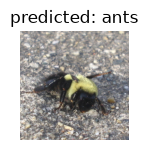

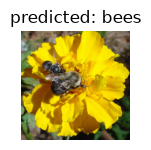

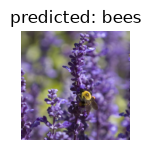

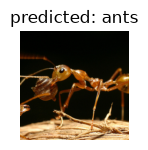

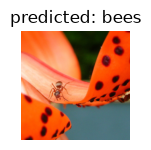

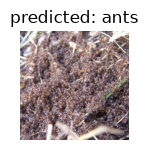

In [ ]:
visualize_model(model_fe)

plt.ioff()
plt.show()